<div style="background-color:#1f3a5f; padding:24px; border-radius:10px; text-align:center;">
  <h1 style="color:white; margin:0;">Predicting Credit Card Fraud</h1>
  <h3 style="color:#a8c4e0; margin:8px 0 0 0;">Kaggle Playground Series S6E11 · 1. Exploratory Data Analysis</h3>
</div>

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
  <h2 style="color:#1f3a5f; margin:0;">1. Load the Data</h2>
</div>

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv") 

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
  <h2 style="color:#1f3a5f; margin:0;">2. Data structure</h2>
</div>

In [3]:
train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [4]:
train.shape

(699960, 26)

In [5]:
train.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [6]:
train.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [7]:
train["is_fraud"].value_counts()

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

In [8]:
train["is_fraud"].value_counts(normalize = True)

is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64

### Data Structure: Key Findings

- **Size:** 699,960 training rows and 26 columns: 24 features, plus `id` and the target `is_fraud`.
- **Feature types:** 13 numeric features and 11 categorical features .
- **Missing values:** none in the numeric columns (every count equals 699,960).
- **`id`** runs from 0 to 699,959. It is a row identifier with no meaning and will be dropped before modelling.

**Target**
- Only **1.67%** of transactions are fraud, a heavily imbalanced target. A model that always predicts "not fraud" would be 98.3% accurate but useless, which is why the competition is scored on **ROC-AUC** and why **StratifiedKFold** is used for validation.

**Skewed features**
- `amount_usd`: median 27, but a maximum of 6,873.
- `account_balance_usd`: median 1,383, but a maximum of 99,701.
- `hours_since_last_txn` and `distance_from_home_km` are also right-skewed.
- These extreme values are kept: in fraud detection, unusual values are often the signal itself. Tree-based models are not affected by skew, but a log scale will be used for plots.

**Small whole-number features**
- `txn_count_last_24h` (0–11), `cvv_retry_count` (0–3), `prior_disputes` (0–4), `day_of_week` (0–6), `time_of_day_hour` (0–23).
- `cvv_retry_count` is 0 for over 75% of transactions, so a retry is rare and may be a strong fraud signal.

**Other observations**
- `card_age_months` ranges from 25 to 73, so every card is at least about 2 years old, likely an artefact of the synthetic data.
- `merchant_risk_score` ranges from 0 to 100.

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
  <h2 style="color:#1f3a5f; margin:0;">3. Explanatory Data Analysis(EDA)</h2>
</div>

In [13]:
fraud_distribution = train["is_fraud"].value_counts(normalize = True)
fraud_labels = ["Not_fraud","Fraud"]

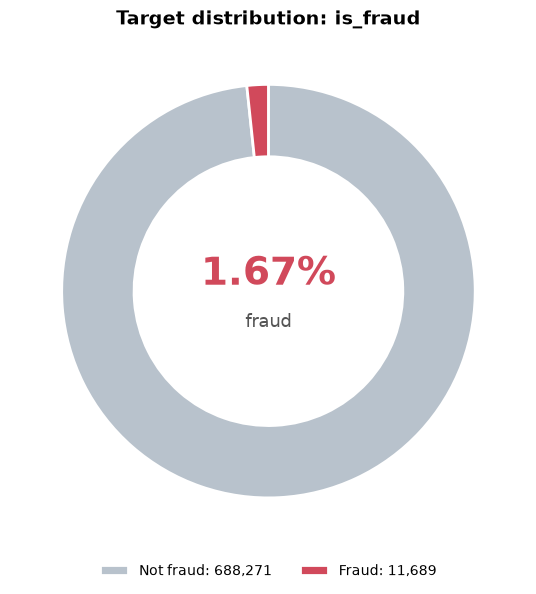

In [16]:
counts = train["is_fraud"].value_counts().sort_index()
pct = counts / counts.sum() * 100
labels = ["Not fraud", "Fraud"]
colors = ["#b8c2cc", "#d1495b"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    counts.values,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.35, "edgecolor": "white", "linewidth": 2},
)

ax.text(0, 0.08, f"{pct[1]:.2f}%", ha="center", va="center",
        fontsize=28, fontweight="bold", color="#d1495b")
ax.text(0, -0.15, "fraud", ha="center", va="center", fontsize=13, color="#555")

ax.legend(
    [f"{l}: {n:,}" for l, n in zip(labels, counts.values)],
    loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False,
)
ax.set_title("Target distribution: is_fraud", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()